# Planificador de misiones v3 (NSGA-II) — cómo generar los resultados

Este notebook usa solo los archivos de esta carpeta:

| Archivo | Para qué sirve |
|---|---|
| `mision_v3.py` | El planificador: mapa de costos, rutas normal/segura, NSGA-II, búsqueda local e ILS |
| `exportar_mision_v3.py` | Genera `salida/rutas_v3.json` (el que lee el visor 3D) |
| `proto1_capas.py` | Carga las capas del mapa de Jezero desde `data/processed/` |

**Flujo:** capas → mapa de costos → candidatos de ciencia → `planear` → frente de Pareto → 4 misiones nombradas → JSON.

In [1]:
# Instala las dependencias EN EL KERNEL que estás usando (solo la primera vez; luego puedes omitirla)
%pip install -q numpy scipy pymoo rasterio matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: C:\Users\Angel\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## 1. Cargar las capas y construir el mapa de costos

In [2]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt

# Carpeta del proyecto: la del notebook, o la que contenga mision_v3.py (VS Code a veces usa otra como cwd)
AQUI = next((d for d in [os.getcwd(), *[os.path.join(os.getcwd(), x) for x in os.listdir(os.getcwd())
             if os.path.isdir(os.path.join(os.getcwd(), x))]] if os.path.exists(os.path.join(d, "mision_v3.py"))), None)
assert AQUI, "No encuentro mision_v3.py: abre la carpeta planificador_v3 en VS Code o haz os.chdir(...) a ella"
os.chdir(AQUI)
sys.path.insert(0, AQUI)

from proto1_capas import cargar, rc_a_xy
import mision_v3 as v3

L = cargar()                               # dem, pendiente, mineralogía CRISM, ruta real...
mapa = v3.Mapa.desde_capas(L)              # costo por celda (inf = pendiente >= 20°)
print("tamaño del mapa:", mapa.forma, "· celdas bloqueadas:", f"{mapa.bloqueado.mean():.1%}",
      "· celdas de riesgo (10-20°):", f"{mapa.riesgo.mean():.1%}")

tamaño del mapa: (1000, 1000) · celdas bloqueadas: 2.1% · celdas de riesgo (10-20°): 13.2%


## 2. Candidatos de ciencia y escenario

Los candidatos son manchas de minerales CRISM con valor y área suficientes. Como en el visor, el escenario es ir del
inicio al final de la ruta real de Perseverance con un presupuesto igual a **factor × la ruta directa**.

In [3]:
cands = v3.candidatos_ciencia(mapa, L)
inicio = tuple(int(v) for v in L["ruta_rc"][0])
meta   = tuple(int(v) for v in L["ruta_rc"][-1])
print(len(cands), "candidatos. Los 5 primeros:")
for c in cands[:5]:
    print(f"  {c['mineral']:<18} área {c['area_ha']:>6.1f} ha · ciencia {c['ciencia']:.3f} · celda {c['celda']}")
print("inicio:", inicio, " meta:", meta)

233 candidatos. Los 5 primeros:
  Mg-Carbonate       área  830.7 ha · ciencia 0.881 · celda (126, 297)
  Mg-Carbonate       área  246.2 ha · ciencia 0.843 · celda (651, 290)
  Mg-Carbonate       área  406.4 ha · ciencia 0.801 · celda (427, 237)
  Olivine+Smectite   área   44.6 ha · ciencia 0.755 · celda (791, 504)
  Olivine+Smectite   área   32.3 ha · ciencia 0.643 · celda (605, 393)
inicio: (454, 561)  meta: (319, 199)


## 3. Correr el planificador

`planear` calcula las rutas entre todos los pares de puntos (Dijkstra) y luego corre el NSGA-II con búsqueda local.
Las opciones están en `OpcionesGA` (población, generaciones, paciencia, semilla...). Tarda unos 10–20 s.

In [4]:
op = v3.OpcionesGA(semilla=42)             # cambia la semilla para otra corrida
plan = v3.planear(mapa, cands, inicio, meta, v3.ROVER, factor=2.0, max_candidatos=15, op=op)

T, pb, frente = plan["tramos"], plan["problema"], plan["frente"]
print(f"{len(plan['candidatos'])} candidatos usados · tramos {plan['seg_tramos']} s · total {plan['seg_total']} s")
print(f"{plan['generaciones']} generaciones · frente de Pareto con {len(frente)} misiones")
print("presupuesto:", {k: round(v, 1) for k, v in plan['presupuesto'].items()})

15 candidatos usados · tramos 8.67 s · total 9.62 s
34 generaciones · frente de Pareto con 9 misiones
presupuesto: {'h': 168.1, 'wh': 4569.1}


## 4. El frente de Pareto

Cada punto es una misión que ninguna otra supera en las tres cosas a la vez: **ciencia** (más es mejor), **horas** y **riesgo_km**
(metros recorridos en pendiente de 10–20°; menos es mejor).

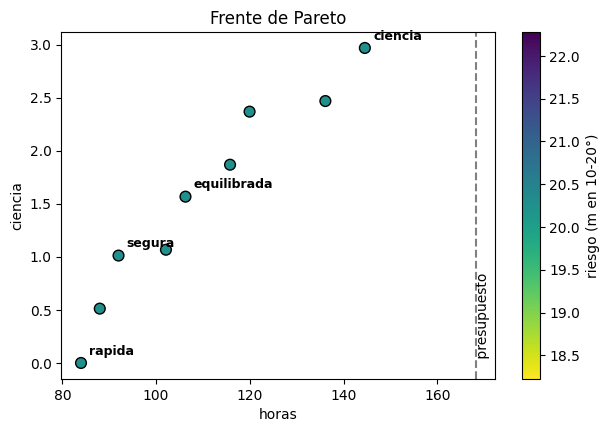

In [5]:
H  = [m["h"] for m in frente]
CI = [m["ciencia"] for m in frente]
RK = [m["riesgo_km"] * 1000 for m in frente]

fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(H, CI, c=RK, cmap="viridis_r", s=60, edgecolor="k")
for nombre, i in plan["nombradas"].items():
    ax.annotate(nombre, (H[i], CI[i]), textcoords="offset points", xytext=(6, 6), fontsize=9, weight="bold")
ax.axvline(plan["presupuesto"]["h"], ls="--", c="gray"); ax.text(plan["presupuesto"]["h"], 0, " presupuesto", rotation=90, va="bottom")
ax.set_xlabel("horas"); ax.set_ylabel("ciencia"); ax.set_title("Frente de Pareto")
fig.colorbar(sc, label="riesgo (m en 10-20°)"); plt.show()

## 5. Las 4 misiones nombradas

`plan["nombradas"]` guarda el índice dentro del frente de cada caso: **ciencia** (la de más ciencia), **rapida** (menos horas),
**segura** (menos riesgo) y **equilibrada** (la más cercana al punto ideal con los objetivos normalizados 0..1). `v3.elegir(frente, pesos)` elige
una con pesos propios.

In [6]:
print(f"{'caso':<12}{'ciencia':>9}{'horas':>8}{'Wh':>7}{'km':>7}{'riesgo m':>10}{'obj':>5}")
for nombre, i in plan["nombradas"].items():
    m = frente[i]
    print(f"{nombre:<12}{m['ciencia']:>9.3f}{m['h']:>8.1f}{m['wh']:>7.0f}{m['km']:>7.2f}{m['riesgo_km']*1000:>10.0f}{len(m['seq']):>5}")

PESOS = {"ciencia": 0.5, "tiempo": 0.3, "riesgo": 0.2}   # los mismos del visor
elegida = frente[v3.elegir(frente, PESOS)]
print("\nelegida con pesos", PESOS, "->", f"ciencia {elegida['ciencia']:.3f}, {elegida['h']:.1f} h, {len(elegida['seq'])} objetivos")

caso          ciencia   horas     Wh     km  riesgo m  obj
ciencia         2.968   144.5   4512  11.09        20    5
rapida          0.000    84.0   2548   8.38        20    0
segura          1.012    92.0   3061   8.38        20    2
equilibrada     1.567   106.3   3370   8.57        20    3

elegida con pesos {'ciencia': 0.5, 'tiempo': 0.3, 'riesgo': 0.2} -> ciencia 2.368, 119.9 h, 4 objetivos


## 6. Dibujar las rutas sobre el terreno

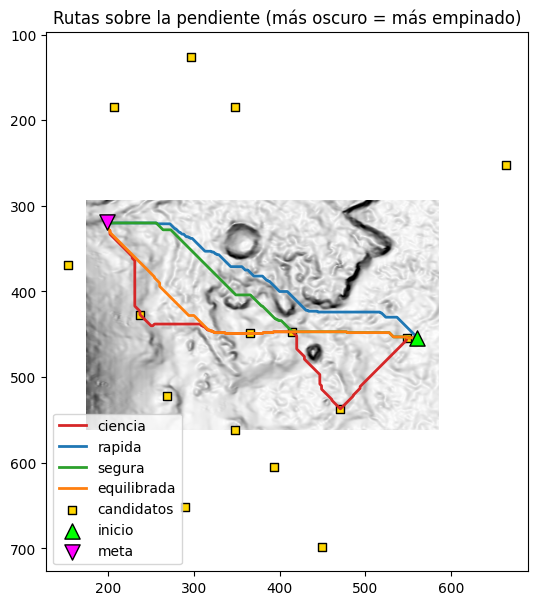

In [7]:
colores = {"ciencia": "tab:red", "rapida": "tab:blue", "segura": "tab:green", "equilibrada": "tab:orange"}
caminos = {n: np.asarray(v3.camino_mision(T, pb, frente[i])) for n, i in plan["nombradas"].items()}

todo = np.vstack(list(caminos.values()))
f0, f1 = todo[:, 0].min() - 25, todo[:, 0].max() + 25
c0, c1 = todo[:, 1].min() - 25, todo[:, 1].max() + 25
f0, c0 = max(int(f0), 0), max(int(c0), 0)

fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(mapa.pend[f0:int(f1), c0:int(c1)], cmap="gray_r", vmin=0, vmax=25,
          extent=(c0, int(c1), int(f1), f0))
for n, cam in caminos.items():
    ax.plot(cam[:, 1], cam[:, 0], c=colores[n], lw=2, label=n)
ax.scatter(*zip(*[(c["celda"][1], c["celda"][0]) for c in plan["candidatos"]]), marker="s", c="gold", edgecolor="k", s=40, label="candidatos")
ax.scatter(inicio[1], inicio[0], c="lime", s=120, edgecolor="k", marker="^", label="inicio", zorder=5)
ax.scatter(meta[1], meta[0], c="magenta", s=120, edgecolor="k", marker="v", label="meta", zorder=5)
ax.set_title("Rutas sobre la pendiente (más oscuro = más empinado)"); ax.legend(loc="best"); plt.show()

## 7. Generar el JSON para el visor

Es exactamente lo que hace `exportar_mision_v3.py`. Se puede correr desde aquí o en terminal:

```
python exportar_mision_v3.py --factor 2.0 --semilla 42 --candidatos 15
```
Opciones: `--factor` (presupuesto = factor × ruta directa), `--semilla`, `--candidatos` (máx. de manchas) y `--salida` (ruta del JSON).
El archivo queda en `salida/rutas_v3.json`; para verlo en el visor 3D cópialo a `visor_3d/public/data/`.

In [8]:
import subprocess
r = subprocess.run([sys.executable, "exportar_mision_v3.py", "--factor", "2.0", "--semilla", "42"],
                   capture_output=True, text=True, cwd=AQUI)
print(r.stdout or r.stderr)

d = json.load(open(os.path.join("salida", "rutas_v3.json"), encoding="utf-8"))
print("claves del JSON:", list(d.keys()))
print("misión elegida:", d["metricas"])
print("nombradas (índices en d['frente']):", d["nombradas"])

15 candidatos Â· tramos 8.48 s Â· total 9.21 s Â· 34 generaciones Â· frente 9
misiÃ³n elegida: 4 objetivos Â· ciencia 2.368 Â· 119.9 h Â· 3791 Wh Â· 9.25 km Â· riesgo 0.02 km
  ciencia      ciencia 2.968 Â· 144.5 h Â· riesgo 0.020 km
  rapida       ciencia 0.000 Â· 84.0 h Â· riesgo 0.020 km
  segura       ciencia 1.012 Â· 92.0 h Â· riesgo 0.020 km
  equilibrada  ciencia 1.567 Â· 106.3 h Â· riesgo 0.020 km
guardado en d:\hackaton\planificador_v3\salida\rutas_v3.json

claves del JSON: ['plan', 'waypoints', 'objetivos', 'inicio', 'meta', 'real', 'metricas', 'presupuesto', 'supuestos', 'frente', 'nombradas']
misión elegida: {'ciencia': 2.368, 'horas': 119.9, 'wh': 3791, 'km': 9.25, 'riesgo_km': 0.02, 'pend_max': 10.3, 'objetivos': 4}
nombradas (índices en d['frente']): {'ciencia': 0, 'rapida': 8, 'segura': 6, 'equilibrada': 4}


## 8. Variantes útiles

- **Más presupuesto:** `factor=2.5` o `3.0` (más ciencia, más horas).
- **Astronauta a pie / EVA:** `agente=v3.ASTRONAUTA`; con `meta=None` es una misión cerrada (ida y vuelta) y `radio_m` limita la distancia.
- **Más búsqueda:** `OpcionesGA(max_gen=200, paciencia=50, timeout_s=60, ils_iter=100)`.
- **El 2.º objetivo del mismo mineral vale menos:** `OpcionesGA(repeticion_mineral=0.5)`.

In [9]:
# Ejemplo: EVA de un astronauta, ida y vuelta desde el inicio, radio de 2 km, 8 h de presupuesto
plan_eva = v3.planear(mapa, cands, inicio, meta=None, agente=v3.ASTRONAUTA, radio_m=2000,
                      presupuesto={"h": 8.0}, max_candidatos=10, op=v3.OpcionesGA(semilla=1))
fr = plan_eva["frente"]
print("frente EVA:", len(fr), "misiones")
for nombre, i in plan_eva["nombradas"].items():
    m = fr[i]; print(f"  {nombre:<12} ciencia {m['ciencia']:.3f} · {m['h']:.1f} h · {m['km']:.2f} km · {len(m['seq'])} objetivos")

frente EVA: 21 misiones
  ciencia      ciencia 1.662 · 6.6 h · 5.25 km · 8 objetivos
  rapida       ciencia 0.512 · 0.7 h · 0.48 km · 1 objetivos
  segura       ciencia 0.786 · 1.8 h · 1.58 km · 2 objetivos
  equilibrada  ciencia 1.179 · 4.1 h · 4.28 km · 4 objetivos
